# Reliable Under Pressure pipeline

Ranking batters and bowlers who perform best in high-pressure match situations, compared with their usual level,
using IPL and T20 International ball-by-ball data (2022–2026).

**Pipeline**
<!-- 
| Step | Stage | What it does |
|---|---|---|
| 1 | Data cleaning (0–3) | Audit and clean deliveries; rebuild score, wickets, balls left and target before every ball; scoring level and opposition strength |
| 2 | Win probability (4) | Models for the batting side's chance of winning before every ball |
| 3 | Pressure (5) | Leverage Index for every ball; the 20% highest in each innings are pressure balls |
| 4 | Expected performance (6, 6b) | What an average player would produce on each ball (context, delivery and shot models) |
| 5 | Ball value (7, 7b) | Runs above expected for every ball, with wickets valued in runs |
| 6 | Player ratings (8, 8c, 9) | Pressure and usual ratings adjusted for sample size, consistency, bootstrap |
| 7 | Final score (10) | Reliability Under Pressure score and eligibility |
| 8 | Validation (11, 12) | Split-half reliability, out-of-time test, rank stability, alternative model settings |
| 9 | Outputs (15) | Final lists, evidence cards, figures | -->


In [1]:
import sys, random
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from pipeline.common.config import load_config
cfg = load_config()
random.seed(cfg["seed"]); np.random.seed(cfg["seed"])

RUN_PIPELINE = True          # False = only show existing outputs
OUT = Path(cfg["paths"]["out"])
TAB, FIG = OUT / "tables", OUT / "figures"
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)

def run(module):
    if RUN_PIPELINE:
        module.run(cfg)

def show(name, width=900):
    path = FIG / name
    if path.exists():
        display(Image(filename=str(path), width=width))

### Data cleaning
Audit the raw files, clean every delivery (legal balls, bowler-charged runs, credited dismissals) and rebuild the match state before every ball.

In [ ]:
from pipeline.preparation import s00_audit, s01_clean, s02_state, s03_env


_header = s00_audit.header

for stage in (s00_audit, s01_clean, s02_state, s03_env):
    run(stage)


STAGE 0 - DATA CLEANING
Row counts:
  ball_by_ball                  200,999
  matches                           883
  competitions                      141
  teams                             353
  playing_eleven                 28,381
  comp_team_player_mapping        6,413
Match date range: 2022-01-22 -> 2026-11-01

Matches with ball data by comp_group x season:
season      2022  2023  2024  2025  2026  All
comp_group                                   
EMERGING       0     0    15    15     0   30
IPL           74    74    71    74    74  367
T20I         106    66   106   122    70  470
All          180   140   192   211   144  867

Emerging competitions: ['Asia Cup Rising Stars 2025', 'Mens T20 Emerging Teams Asia Cup 2024']

Data-pack fact checks
  [PASS] ball_by_ball rows = 200,999 (got 200,999)
  [PASS] 867 matches with balls (got 867)
  [PASS] matches.csv rows = 883 (got 883)
  [PASS] competitions rows = 141 (got 141)
  [PASS] mapping data rows = 6,413 (6,414 lines include the

### Win probability model
Two gradient-boosted models (first innings and chase), each match predicted by a model trained on other matches.


STAGE 4 - WIN-PROBABILITY MODELS
training matches: 830 of 867 (excluded: NR/tie/suspect/DLS-par-finish 37)
chase-start logistic (OOF, first chase ball, n=830): log-loss 0.5620, AUC 0.7820
sd of final first-innings total (IPL 2026 env, runs) at balls_left 120/60/24/6/1: 39.6, 24.0, 14.2, 6.8, 3.7

Endgame DP weight selection (chase, OOF log-loss)
  1 ball(s) left (n=283): w=1.00: LL 0.1053, w=0.75: LL 0.1094, w=0.50: LL 0.1167  -> chosen w=1.0
  2 ball(s) left (n=339): w=0.50: LL 0.1514, w=0.25: LL 0.1583, w=0.00: LL 0.1749  -> chosen w=0.5
  3 ball(s) left (n=376): w=0.25: LL 0.1730, w=0.00: LL 0.1799  -> chosen w=0.25
  innings-1 blend over last 120 balls: log-loss on blended rows 0.6386 (unblended) -> 0.6291 (blended), n=101,501

Acceptance
  WP1: AUC 0.6956 | Brier 0.2202 | logloss 0.6297 | ECE 0.0156 (raw 0.0087, isotonic=False) | n=102,387 | base rate 0.499
  WP2: AUC 0.9032 | Brier 0.1262 | logloss 0.3903 | ECE 0.0108 (raw 0.0109, isotonic=False) | n=93,814 | base rate 0.481
  [

,WP1,WP2
auc,0.695606,0.903221
brier,0.220199,0.126203
logloss,0.629712,0.390260
ece,0.015647,0.010762


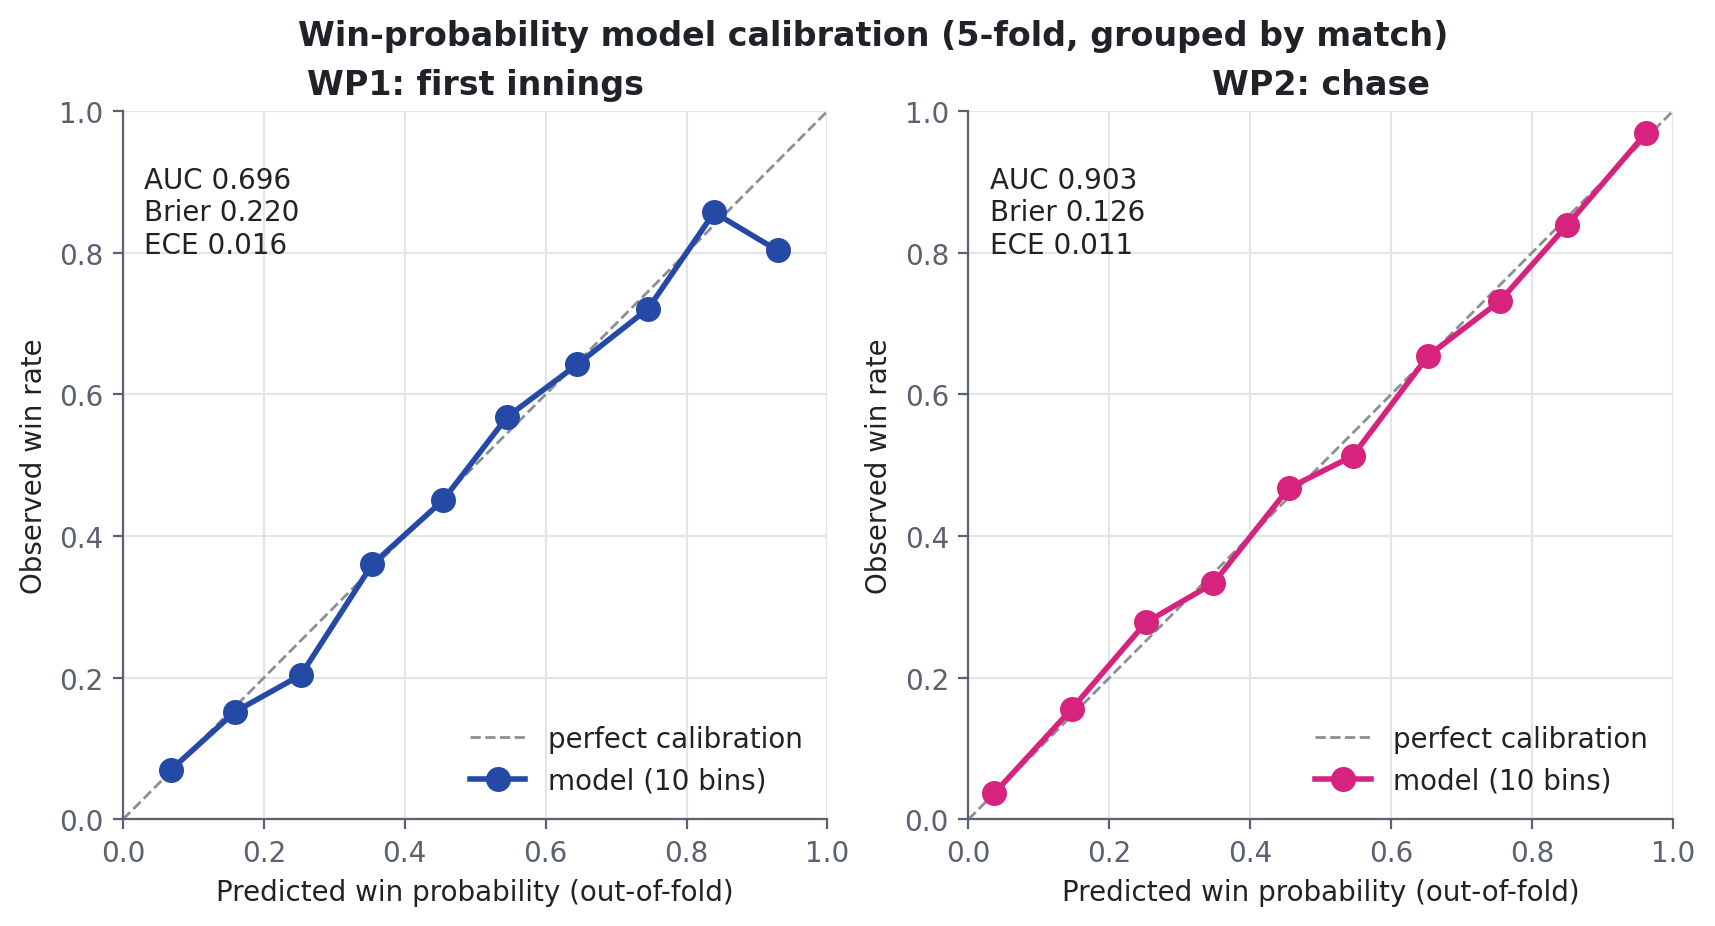

In [3]:
from pipeline.pressure import s04_wp_models
run(s04_wp_models)
display(pd.read_json(TAB / "wp_metrics.json").loc[["auc", "brier", "logloss", "ece"], ["WP1", "WP2"]])
show("wp_calibration.png")

### Pressure: Leverage Index
How much each ball can change the win probability (ordinary ball = 1). Pressure ball = one of the 20% highest in its innings.


STAGE 5 - LEVERAGE INDEX
outcome-probability buckets: 57 (smallest n 3; 12 buckets with n < alpha=300 lean mostly on their parent)
  e.g. chase, death overs, 4-5 down: p(dot) / p(4) / p(6) / p(wicket) by required-rate band
    rrr 10-12  n=  757  0.193 / 0.110 / 0.078 / 0.077
    rrr 8-10   n=  758  0.190 / 0.120 / 0.079 / 0.056
    rrr <8     n= 1823  0.214 / 0.123 / 0.070 / 0.062
    rrr >12    n= 2754  0.167 / 0.111 / 0.108 / 0.086
computing LI_raw (8 hypothetical outcomes x 200,961 balls)...

Innings-break continuity
  WP1 before last ball vs 1 - WP2 at first chase ball (834 completed innings): mean gap +0.0159, mean |gap| 0.0476, p90 |gap| 0.1013
  innings-end value (smooth chase-start curve) vs tree WP2 at first chase ball: mean |gap| 0.0439, mean +0.0102
  mean LI: balls 103-114 1.259 | last 6 balls 1.287 (ratio 1.02) | balls 115-119 1.273 | final ball 1.363
  [PASS] no systematic WP jump across the break (|mean gap| 0.0159 <= 0.03)
  [PASS] final ball of innings 1 not inflated

,innings,n_balls,total_abs_dwp,top10_share_of_abs_dwp,top20_share_of_abs_dwp,top30_share_of_abs_dwp
0,1,105727,931.512061,0.174571,0.319582,0.448896
1,2,95234,1541.931288,0.404317,0.591057,0.719669


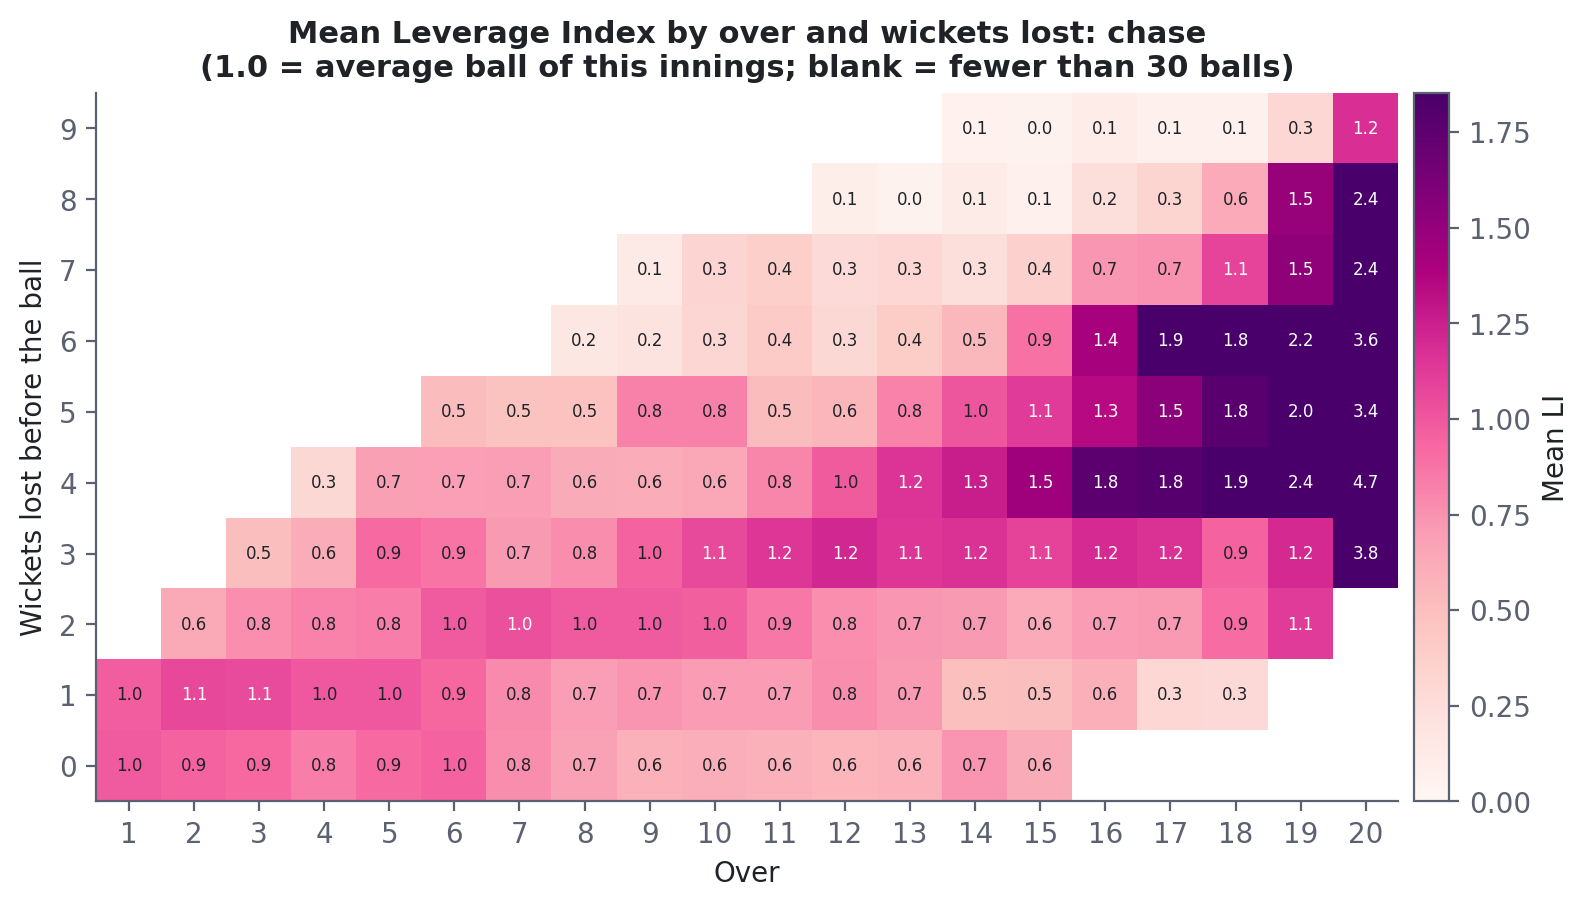

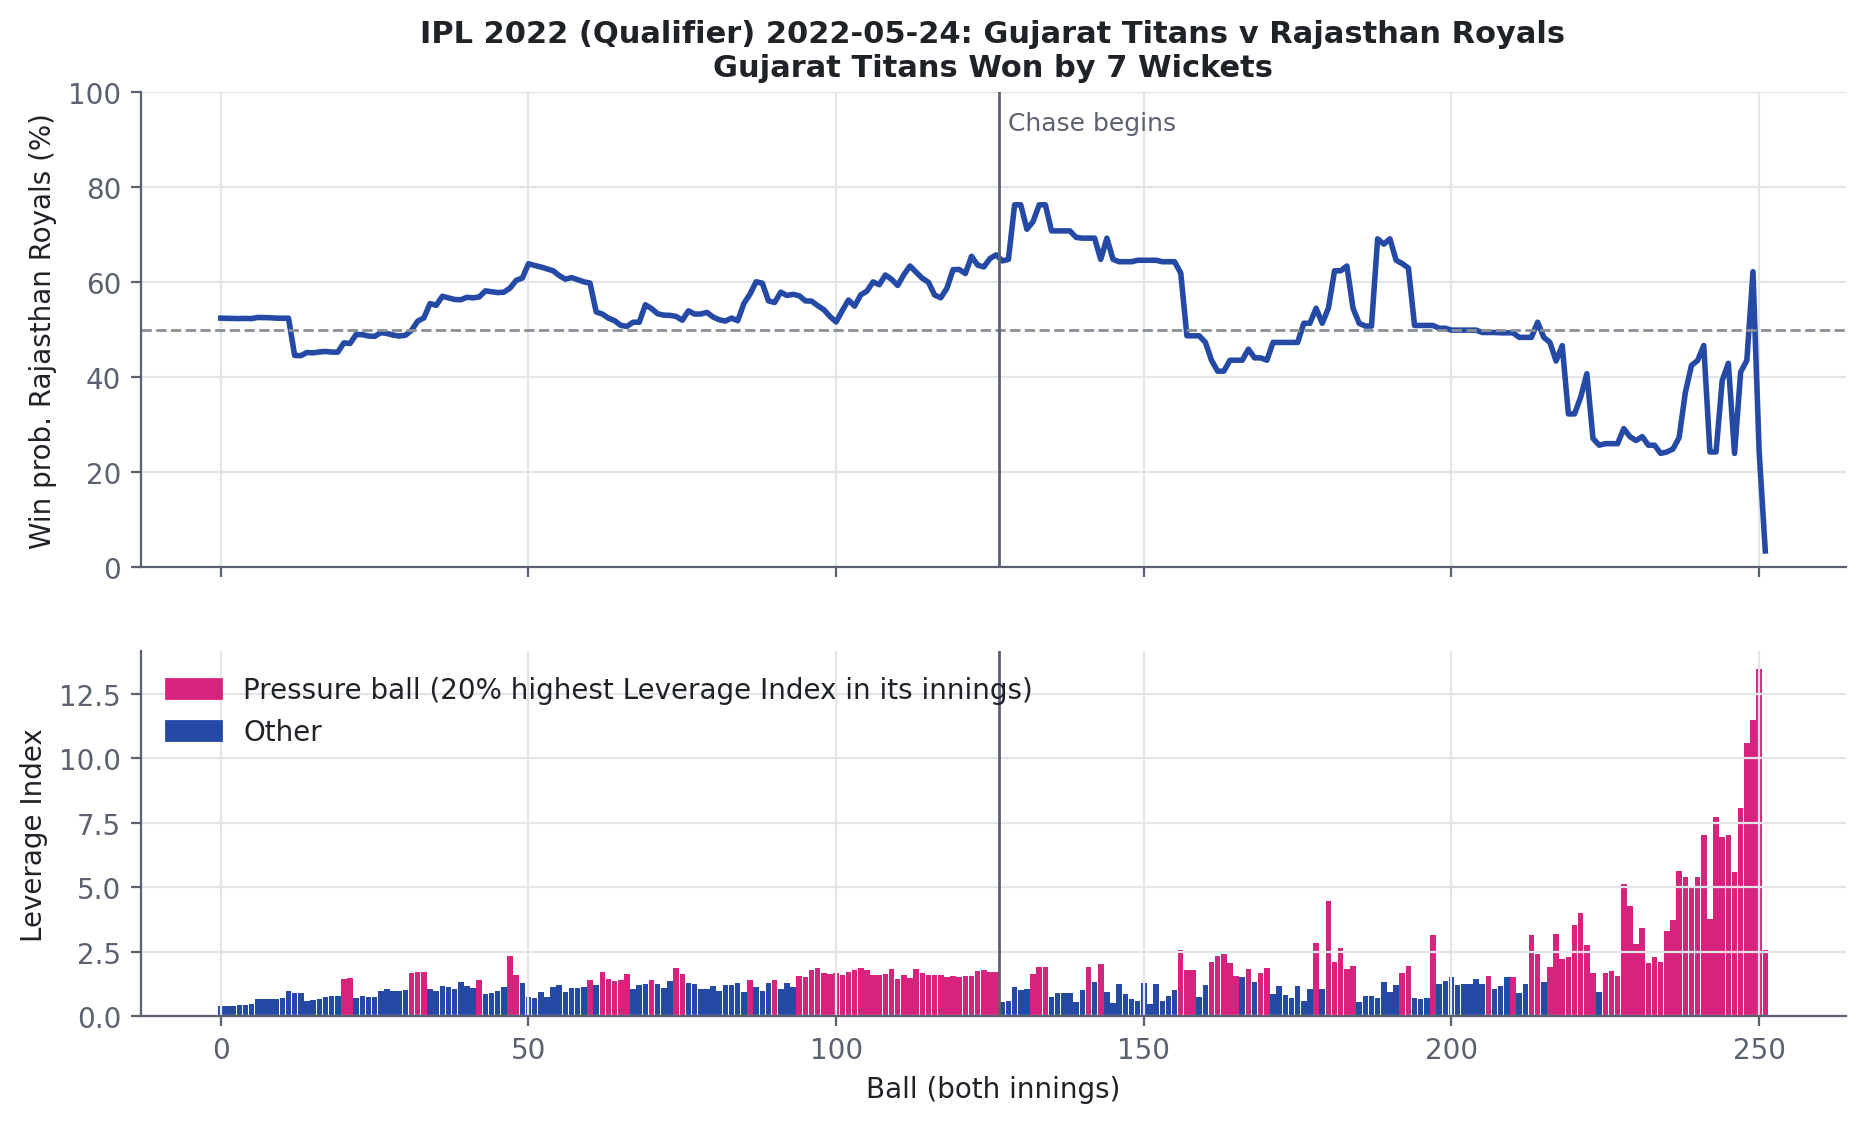

In [4]:
from pipeline.pressure import s05_leverage
run(s05_leverage)
display(pd.read_csv(TAB / "li_concentration.csv"))
show("li_heatmap_inn2.png"); show("example_match_ipl_playoff_15187.png")

### Expected performance
Context models (situation, conditions, opposition, match-up) and process models (delivery type and shot type).

In [5]:
from pipeline.value import s06_expected, s07_ball_value, s06b_process_models, s07b_process_value
run(s06_expected)


STAGE 6 - EXPECTED OUTCOMES AND WICKET RUN-VALUE
  [PASS] using the same match folds as Stage 4
features (batter models): ['innings', 'over_num', 'over_ball_c', 'phase_code', 'wkts_before', 'balls_left', 'score_before', 'rrr', 'runs_needed', 'need_ratio', 'wp_before', 'env_rpb', 'tier_code', 'opp_bowl_strength_rel', 'opp_bowl_wpb_rel', 'is_spin']
features (bowler models): ['innings', 'over_num', 'over_ball_c', 'phase_code', 'wkts_before', 'balls_left', 'score_before', 'rrr', 'runs_needed', 'need_ratio', 'wp_before', 'env_rpb', 'tier_code', 'opp_bat_strength_rel', 'opp_bat_wpb_rel', 'is_lhb']
  [PASS] no raw target / player or team identity features
  fitting xR_bat ...
  fitting xO_bat ...
  fitting xDot_bat ...
  fitting xBnd_bat ...
  fitting xR_bowl ...
  fitting xW_bowl ...
  [PASS] out-of-fold: no fold's predictions come from a model trained on that fold
  [PASS] every eligible ball has OOF expectations

Model skill (OOF) vs a phase x innings x wickets-bucket mean baseline
  xR_b

### Ball value: runs above expected
Actual result minus the average player's expected result, with a wicket counted as the runs it costs.


STAGE 7 - BALL VALUE

Centring (by construction ~0)
  mean v_bat per ball faced:  +0.0017 runs (sum +333 over 193,063 balls)
  mean v_bowl per delivery:   -0.0026 runs (sum -513 over 200,767 deliveries)
  non-striker run-outs: 271 balls, total penalty -1355 runs (-0.0070 per ball faced if folded in)
  [PASS] mean v_bat and v_bowl within ±0.02 runs per ball
  v_bat parts: runs -0.0055, wicket +0.0071
  v_bowl parts: runs +0.0043, wicket -0.0066
  [PASS] dwp telescopes within each innings (max error 1.11e-16)
  share of |dwp| credited to batters: 96.4%; to bowlers: 97.8% (rest: byes/leg-byes/penalty, run-outs)
  wpa/LI: LI floor 0.05 binds on 6.2% of balls; |wpa_bat/LI| p99 0.133

Face validity: top 10 by total runs above expected (all balls, no tuning)
  batters:
                            name  balls  runs       v  v_per100   wpa
striker_id                                                           
1699            Suryakumar Yadav   2759  4588  794.27     28.79  5.57
6281            

,scope,ball_type,balls,raw_SR,expected_SR,dismissal_pct,expected_dismissal_pct,boundary_pct,expected_boundary_pct,dot_pct,expected_dot_pct,v_bat_per100
0,all,normal,154688.0,137.695878,138.287497,5.268670,5.281270,18.505637,18.552969,37.739191,37.725448,0.007711
1,all,pressure,38375.0,146.618893,146.951305,6.233225,6.258315,19.351140,19.214454,34.397394,34.375743,0.837328


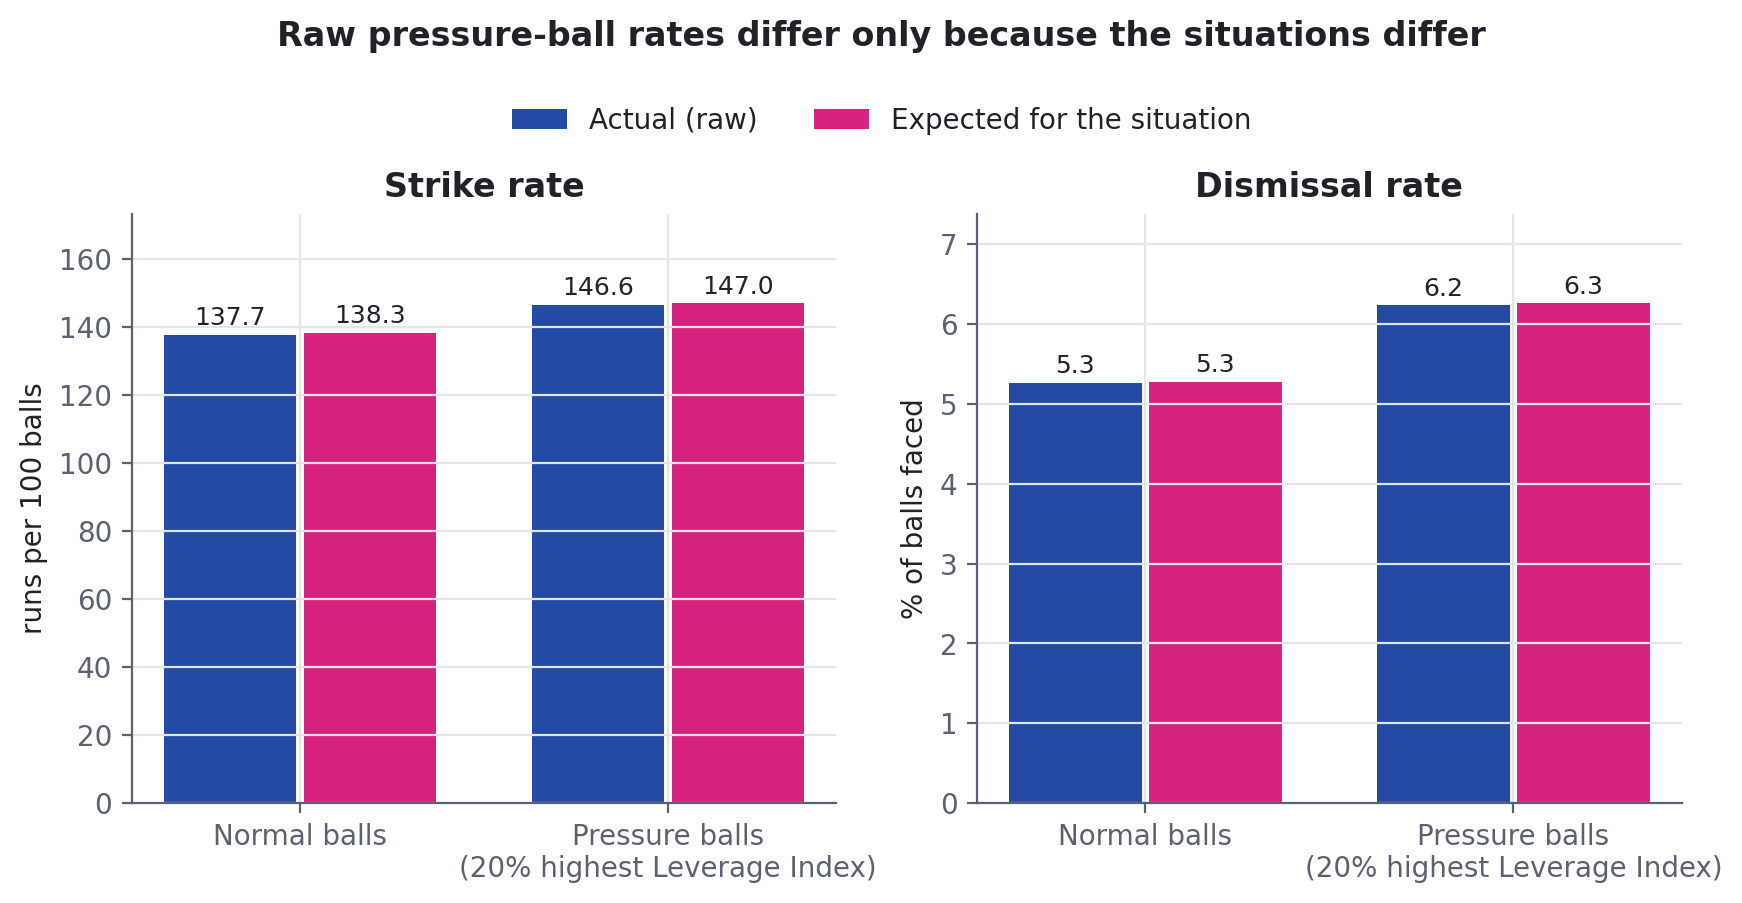

In [6]:
run(s07_ball_value); run(s06b_process_models); run(s07b_process_value)
display(pd.read_csv(TAB / "raw_sr_trap.csv").head(2))
show("raw_sr_trap.png")

### Player ratings, consistency and bootstrap
Pressure and usual ratings per 100 balls, adjusted for sample size; consistency across pressure matches; 1,000 resampled re-runs.

In [7]:
from pipeline.ratings import s08_player_ratings, s08c_process_ratings, s09_consistency
for stage in (s08_player_ratings, s08c_process_ratings, s09_consistency):
    run(stage)


STAGE 8 - PLAYER RATINGS
ball weights: recency half-life 730 days to 2026-11-15, tiers {'IPL': 1.0, 'T20I_FM': 1.0, 'T20I_ASSOC': 0.5, 'EMERGING': 0.6}; mean weight 0.458, IPL 2026 ball 0.826, IPL 2022 ball 0.206

Batting: empirical-Bayes shrinkage
  sigma^2 per ball: pressure 6.210, normal 7.988 (runs^2)
  [REML] true baseline spread sd(B) = 12.27 per 100 balls (95% CI 9.76-14.98; 579 players)
  [REML] true clutch spread sd(P-B) = 0.32 per 100 balls (95% CI 0.00-9.86; 321 players) -> using the upper bound 9.86
  k_B = 530.5 effective balls | k_P = 639.2 effective pressure balls (clutch point estimate would give 620957; spec-literal 580)
  -> a batter needs ~531 normal balls before his baseline counts as much as the league prior, and ~639 pressure balls before his pressure record counts as much as his own baseline.
  [PASS] bat: finite positive k values
  players with >= 100 pressure balls: 125; shrink weight on own pressure record: median 0.19, max 0.43
  spread among them (per 100 b

### Final score and eligibility

In [8]:
from pipeline.ratings import s10_composite
run(s10_composite)


STAGE 10 - FINAL RATING: RELIABILITY UNDER PRESSURE (RUP)
  availability, nationality, Pakistan flag and RR membership are informational columns only.

Batting: temporal test (train <= 2025-12-31, target = IPL 2026 raw pressure outcome)
  train: 167,879 balls; outcome k_B 527 / k_P 892; process k_B 84 / k_P 125; test: 17,523 balls
  analysis set: 19 players (>= 40 test and >= 30 train pressure balls); Spearman 95% CI half-width ~0.49
  [PASS] bat: analysis set >= 15 players (19)
  blend weight a (0 = outcome only, 1 = process only): Spearman(train R_P, IPL 2026 raw pressure outcome)
  a    rho     lo    hi  boot_mean  vs_outcome_only_lo  vs_outcome_only_hi
0.0 -0.033 -0.523 0.461     -0.043               0.000               0.000
0.1 -0.032 -0.514 0.439     -0.040              -0.135               0.144
0.2 -0.042 -0.523 0.428     -0.052              -0.142               0.138
0.3 -0.082 -0.542 0.382     -0.088              -0.266               0.180
0.4 -0.079 -0.510 0.373     -0.082

### Validation and robustness
Split-half reliability, out-of-time test on IPL 2026, rank stability and 29 alternative model settings.


STAGE 11 - VALIDATION

d) Model quality (Stages 4, 6, 6b)
  [PASS] figure wp_calibration.png present
  [PASS] table expected_calibration.csv present
  [PASS] table process_calibration.csv present
  [PASS] table process_calibration_season.csv present
  {}

a) Split-half reliability (bat): odd vs even matches, Spearman-Brown
metric                n  P_raw  B_raw  D_raw  P_star  proc_P_raw  proc_B_raw  proc_D_raw  proc_P_star     C
min_pressure_balls                                                                                         
20                  330  -0.09   0.07  -0.29    0.30        0.34        0.58        0.16         0.68  0.14
40                  222  -0.06   0.13  -0.27    0.38        0.40        0.67        0.10         0.73  0.18
60                  178   0.12   0.14  -0.02    0.41        0.44        0.68        0.15         0.73  0.24
80                  151  -0.03   0.16  -0.16    0.41        0.46        0.76        0.19         0.75  0.26
100                 125  -

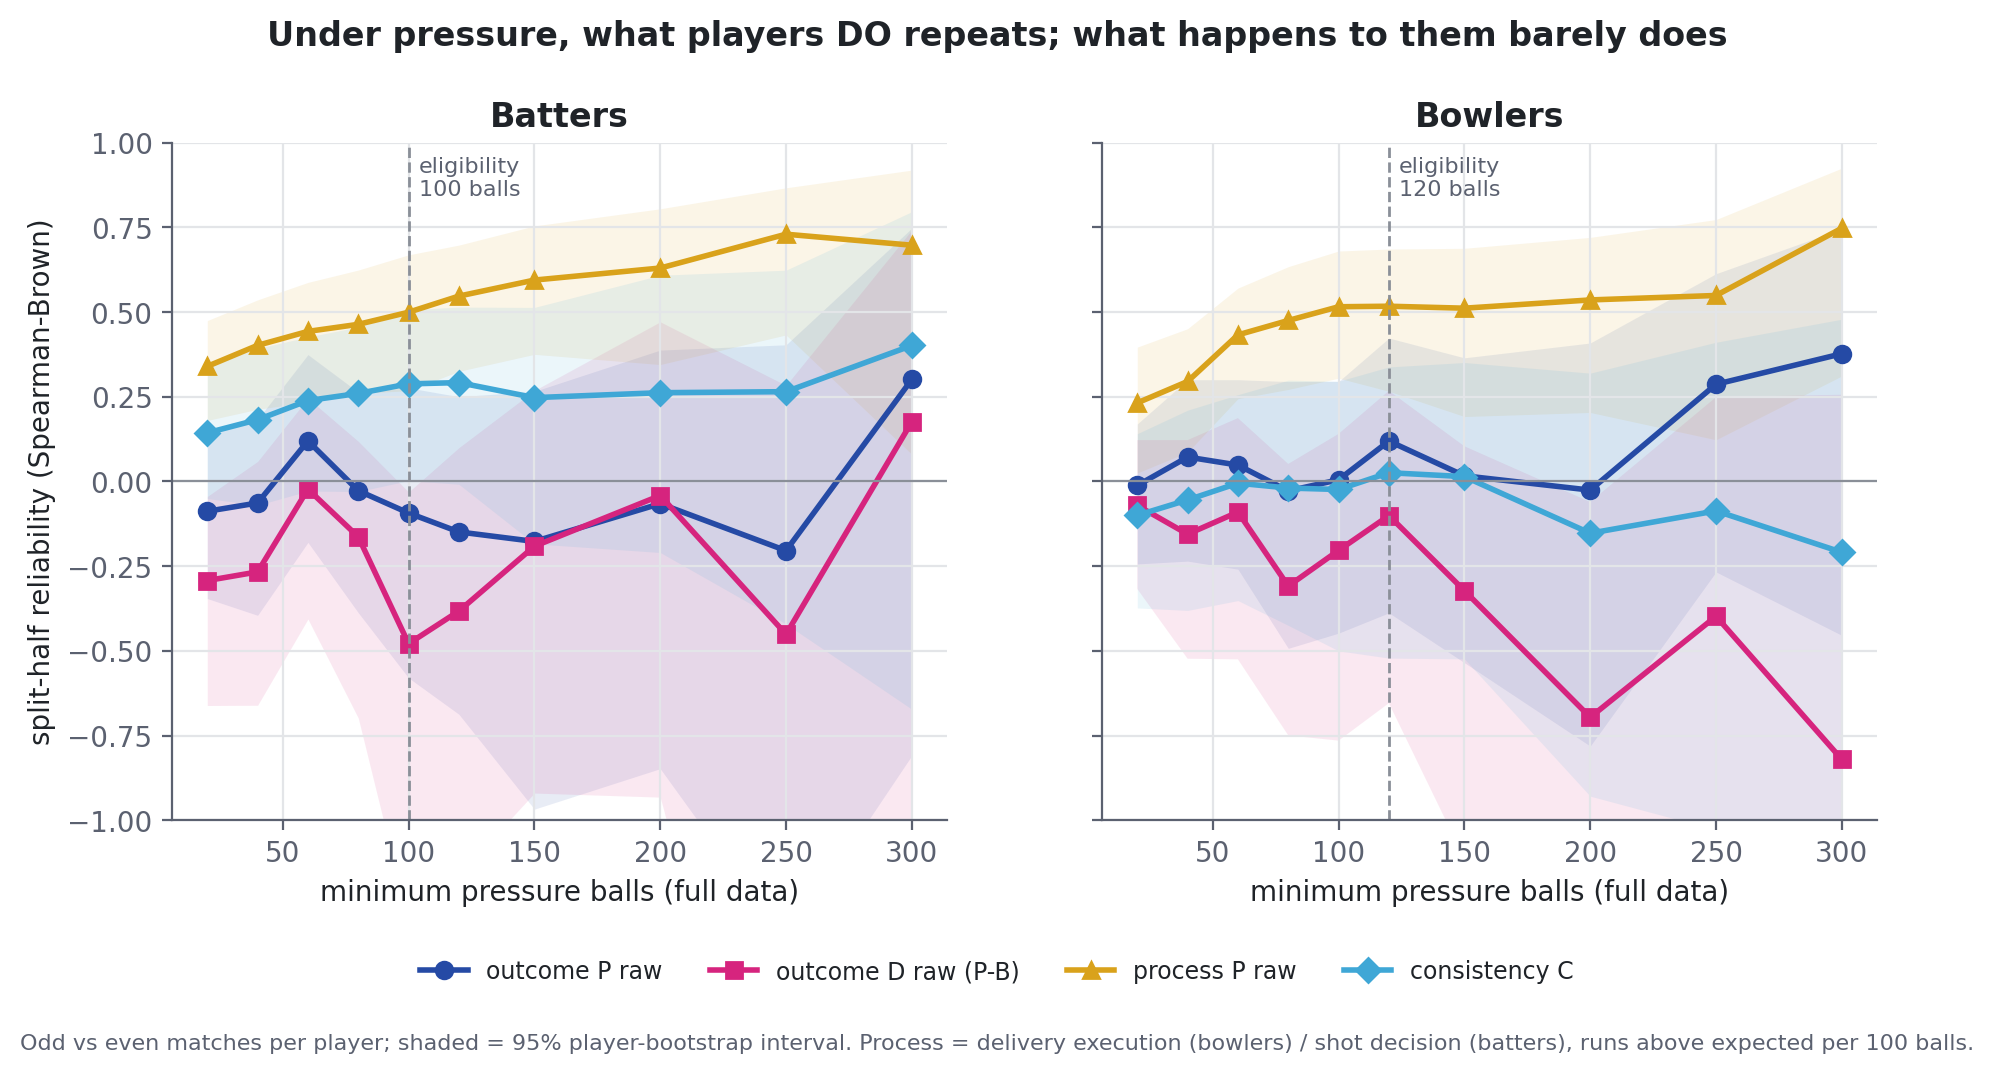

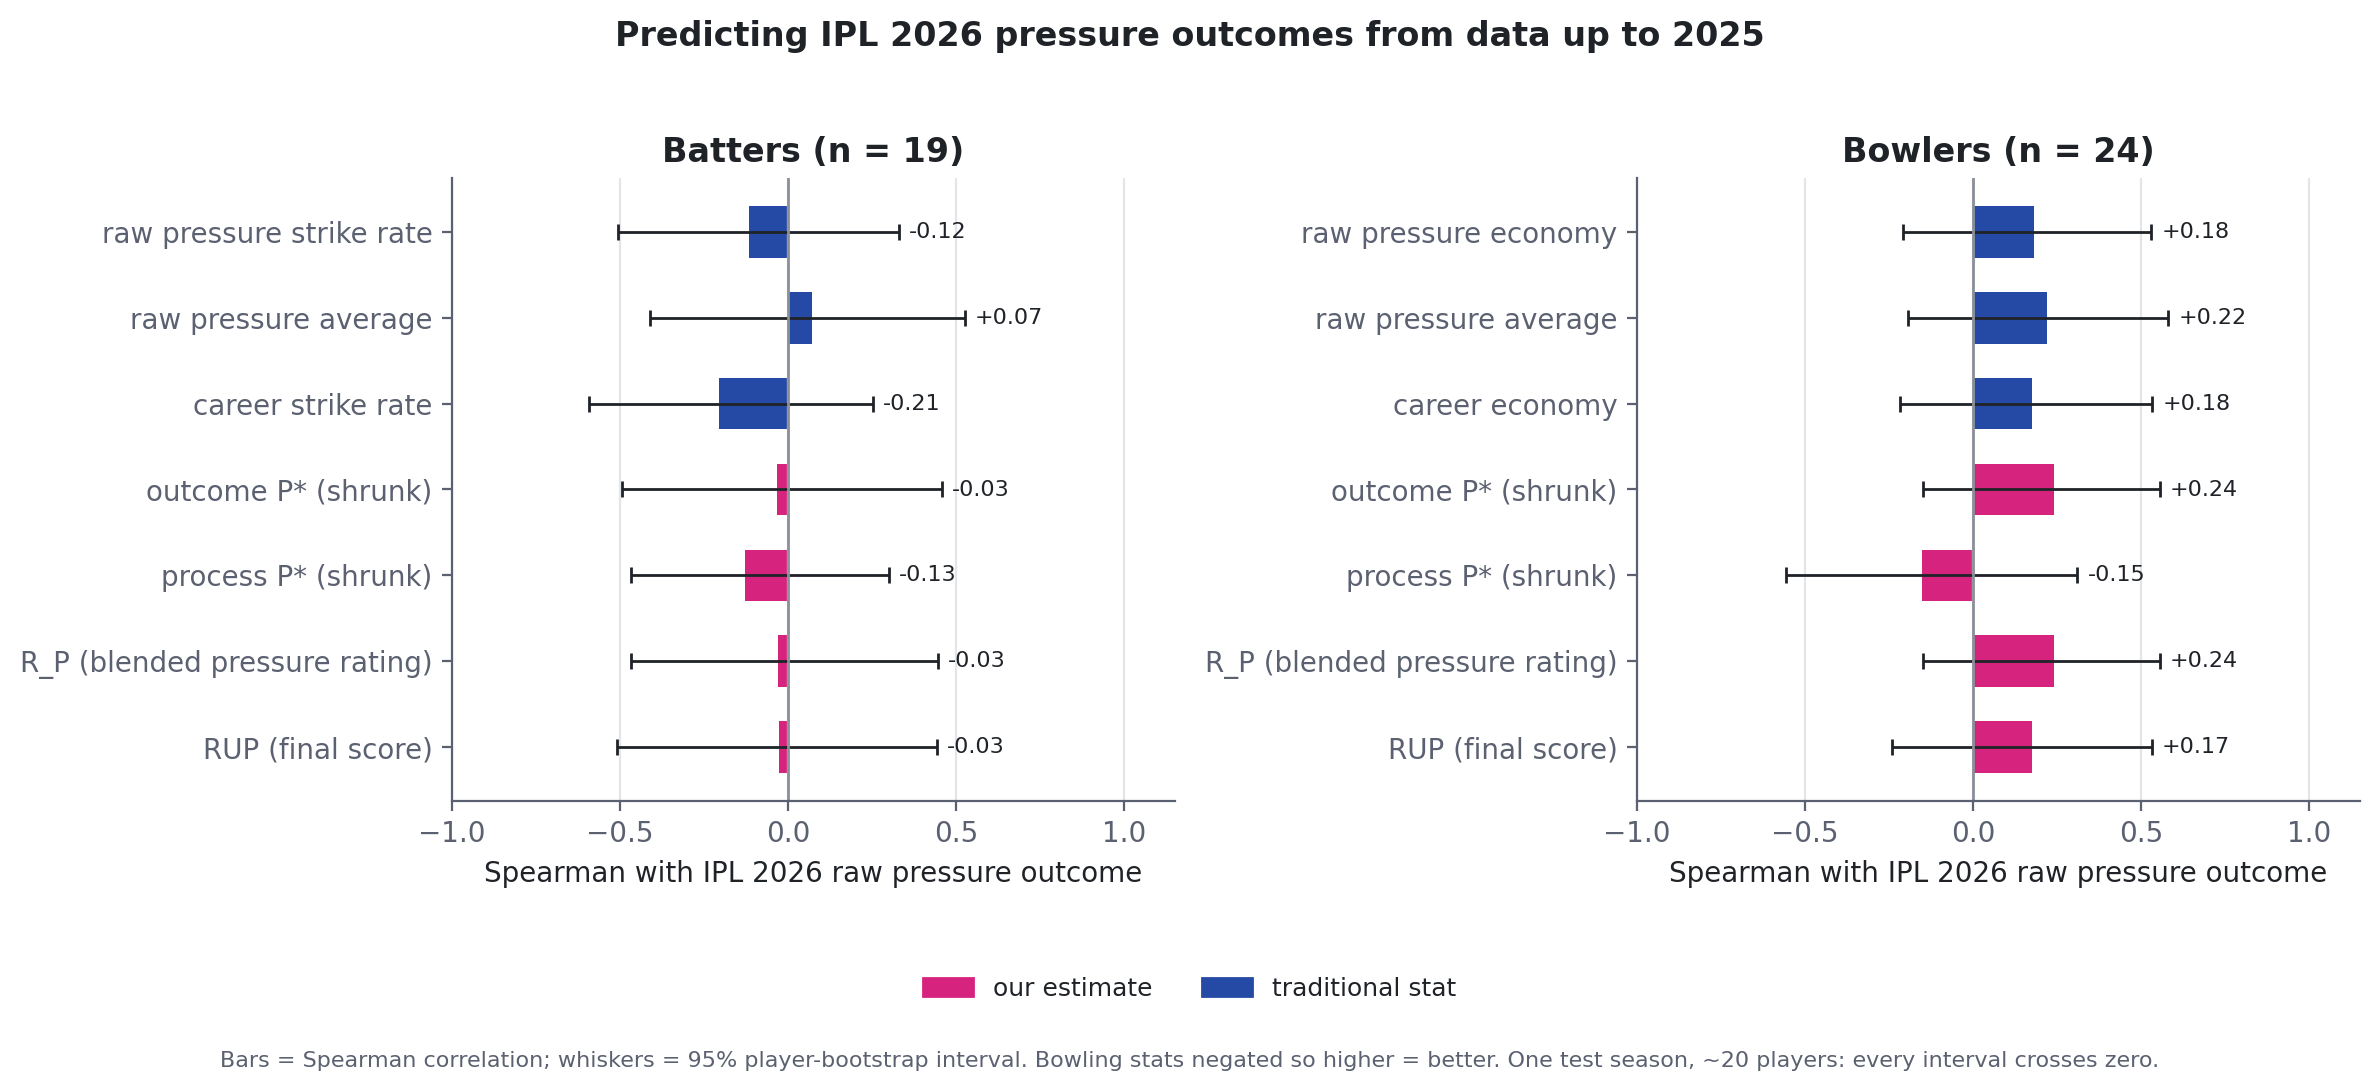

In [9]:
from pipeline.validation import s11_validation, s12_sensitivity
run(s11_validation); run(s12_sensitivity)
show("reliability_curve.png"); show("temporal_validity.png")